#### **1. Read Dataset**

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [2]:
# Menentukan lokasi folder
ROOT = Path.cwd()

if not (ROOT / "data").exists():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"

# Membaca dataset
df = pd.read_csv(DATA_DIR / "train.csv")
df_test = pd.read_csv(DATA_DIR / "test.csv")
df_sample = pd.read_csv(DATA_DIR / "sample_submission.csv")
df_metadata = pd.read_csv(DATA_DIR / "metadata.csv")

# Menentukan kolom target dan ID
TARGET = "damage_grade"
ID_COL = "building_id"

print("Dataset berhasil dibaca.")

Dataset berhasil dibaca.


In [3]:
print("Training Data:", df.shape)
print("Testing Data:", df_test.shape)
print("Sample Submission:", df_sample.shape)
print("Metadata:", df_metadata.shape)

Training Data: (533465, 17)
Testing Data: (228629, 16)
Sample Submission: (228629, 2)
Metadata: (27, 3)


In [4]:
print("Training Data:")
display(df.head())

print("Testing Data:")
display(df_test.head())

print("Sample Submission:")
display(df_sample.head())

print("Metadata:")
display(df_metadata.head())

Training Data:


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


Testing Data:


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,superstructure
0,122207000141,12,1205,120504,1,8,240,10,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,Not applicable,Not attached,Rectangular,has_superstructure_mud_mortar_stone
1,284909000871,28,2810,281006,3,4,384,22,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,has_superstructure_mud_mortar_stone
2,241904000231,24,2409,240909,2,999,384,21,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,has_superstructure_mud_mortar_stone
3,248308000891,24,2412,241202,2,16,527,19,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,has_superstructure_mud_mortar_stone
4,300405002981,30,3001,300104,2,6,280,16,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,Timber-Planck,Not attached,Rectangular,has_superstructure_mud_mortar_stone


Sample Submission:


,building_id,damage_grade
0,122207000141,Grade 3
1,284909000871,Grade 1
2,241904000231,Grade 5
3,248308000891,Grade 4
4,300405002981,Grade 2


Metadata:


,Variable,Description,Type
0,building_id,A unique ID that identifies a unique building ...,Text
1,district_id,District where the building is located,Text
2,vdcmun_id,Municipality where the building is located,Text
3,ward_id,Ward Number in which the building is located,Text
4,count_floors_pre_eq,Number of floors that the building had before ...,Number


#### **2. Quick EDA**

##### Pemeriksaan Kolom dan Target

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 533465 entries, 0 to 533464
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   building_id             533465 non-null  int64
 1   district_id             533465 non-null  int64
 2   vdcmun_id               533465 non-null  int64
 3   ward_id                 533465 non-null  int64
 4   count_floors_pre_eq     533465 non-null  int64
 5   age_building            533465 non-null  int64
 6   plinth_area_sq_ft       533465 non-null  int64
 7   height_ft_pre_eq        533465 non-null  int64
 8   land_surface_condition  533465 non-null  str  
 9   foundation_type         533465 non-null  str  
 10  roof_type               533465 non-null  str  
 11  ground_floor_type       533465 non-null  str  
 12  other_floor_type        533465 non-null  str  
 13  position                533465 non-null  str  
 14  plan_configuration      533465 non-null  str  
 15  damage_grad

In [6]:
print("Kolom Training:")
print(df.columns.tolist())

print("\nKolom Testing:")
print(df_test.columns.tolist())

Kolom Training:
['building_id', 'district_id', 'vdcmun_id', 'ward_id', 'count_floors_pre_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq', 'land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'damage_grade', 'superstructure']

Kolom Testing:
['building_id', 'district_id', 'vdcmun_id', 'ward_id', 'count_floors_pre_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq', 'land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'superstructure']


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
building_id,533465.0,2.607139e+11,5.806563e+10,1.201010e+11,2.219060e+11,2.463010e+11,3.036070e+11,3.667090e+11
district_id,533465.0,2.576413e+01,5.812230e+00,1.200000e+01,2.200000e+01,2.400000e+01,3.000000e+01,3.600000e+01
vdcmun_id,533465.0,2.582312e+03,5.816406e+02,1.201000e+03,2.204000e+03,2.410000e+03,3.010000e+03,3.611000e+03
ward_id,533465.0,2.582367e+05,5.816413e+04,1.201010e+05,2.204010e+05,2.410040e+05,3.010050e+05,3.611080e+05
count_floors_pre_eq,533465.0,2.088000e+00,6.550006e-01,1.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,9.000000e+00
age_building,533465.0,2.433732e+01,6.499906e+01,0.000000e+00,9.000000e+00,1.600000e+01,2.700000e+01,9.990000e+02
plinth_area_sq_ft,533465.0,4.065235e+02,2.266105e+02,7.000000e+01,2.800000e+02,3.580000e+02,4.700000e+02,5.000000e+03
height_ft_pre_eq,533465.0,1.604768e+01,5.490926e+00,6.000000e+00,1.200000e+01,1.600000e+01,1.800000e+01,9.900000e+01


In [8]:
print("Distribusi Damage Grade:")
display(df[TARGET].value_counts().sort_index())

Distribusi Damage Grade:


damage_grade
Grade 1     55170
Grade 2     61080
Grade 3     95488
Grade 4    128691
Grade 5    193036
Name: count, dtype: int64

#### **3. Data Quality Analysis**

##### **Cek Missing Value**

In [9]:
missing_summary = pd.DataFrame({
    "Jumlah Missing": df.isna().sum(),
    "Persentase (%)": (df.isna().mean() * 100).round(2)
})

display(
    missing_summary[
        missing_summary["Jumlah Missing"] > 0
    ].sort_values(
        by="Jumlah Missing",
        ascending=False
    )
)

if df.isna().sum().sum() == 0:
    print("Tidak terdapat missing value pada dataset training.")

,Jumlah Missing,Persentase (%)


Tidak terdapat missing value pada dataset training.


In [10]:
missing_count = df.isna().sum()
missing_count = missing_count[missing_count > 0].sort_values(
    ascending=False
)

if len(missing_count) > 0:
    missing_count.head(20).plot(
        kind="bar",
        figsize=(12, 5)
    )

    plt.title("Missing Values per Feature")
    plt.xlabel("Feature")
    plt.ylabel("Jumlah Missing Value")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada missing value untuk divisualisasikan.")

Tidak ada missing value untuk divisualisasikan.


##### **Cek Duplikasi**

In [11]:
# Memeriksa ID bangunan
if ID_COL in df.columns:
    print(
        "Duplikasi building_id pada training:",
        df[ID_COL].duplicated().sum()
    )

if ID_COL in df_test.columns:
    print(
        "Duplikasi building_id pada testing:",
        df_test[ID_COL].duplicated().sum()
    )

# Pemeriksaan duplikasi baris pada sampel
sample_df = df.sample(
    n=min(20000, len(df)),
    random_state=42
)

print(
    "Duplikasi baris pada sampel:",
    sample_df.duplicated().sum()
)

Duplikasi building_id pada training: 0
Duplikasi building_id pada testing: 0
Duplikasi baris pada sampel: 0


##### **Pemeriksaan ID antara Training dan Testing**

In [12]:
if ID_COL in df.columns and ID_COL in df_test.columns:
    train_ids = set(df[ID_COL])
    test_ids = set(df_test[ID_COL])

    print("Jumlah ID training:", len(train_ids))
    print("Jumlah ID testing:", len(test_ids))
    print("ID overlap:", len(train_ids.intersection(test_ids)))
else:
    print("Kolom building_id tidak tersedia pada salah satu dataset.")

Jumlah ID training: 533465
Jumlah ID testing: 228629
ID overlap: 0


#### **4. Feature Analysis**

##### **Identifikasi Fitur Numerik dan Kategorikal**

In [13]:
# Fitur yang bukan ID dan bukan target
feature_cols = [
    col for col in df.columns
    if col not in [ID_COL, TARGET]
]

# Fitur geografis diperlakukan sebagai kategori
geo_features = [
    col for col in feature_cols
    if col.startswith("geo_level_")
]

# Kolom kategorikal berdasarkan tipe data
categorical_features = df[feature_cols].select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Kolom biner, seperti fitur has_superstructure
binary_features = [
    col for col in feature_cols
    if df[col].nunique(dropna=True) <= 2
]

# Menggabungkan kategori tanpa duplikasi
categorical_features = list(dict.fromkeys(
    categorical_features + geo_features + binary_features
))

# Fitur numerik lainnya
numerical_features = [
    col for col in df.select_dtypes(include=np.number).columns
    if col in feature_cols and col not in categorical_features
]

print("Jumlah fitur numerik:", len(numerical_features))
print("Jumlah fitur kategorikal:", len(categorical_features))

print("\nFitur Numerik:")
print(numerical_features)

print("\nFitur Kategorikal:")
print(categorical_features)

Jumlah fitur numerik: 7
Jumlah fitur kategorikal: 8

Fitur Numerik:
['district_id', 'vdcmun_id', 'ward_id', 'count_floors_pre_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq']

Fitur Kategorikal:
['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'superstructure']


##### **Statistika Deskriptif Fitur Numerik**

In [14]:
if numerical_features:
    display(df[numerical_features].describe().T)
else:
    print("Tidak ada fitur numerik untuk dianalisis.")

,count,mean,std,min,25%,50%,75%,max
district_id,533465.0,25.764134,5.812230,12.0,22.0,24.0,30.0,36.0
vdcmun_id,533465.0,2582.312433,581.640567,1201.0,2204.0,2410.0,3010.0,3611.0
ward_id,533465.0,258236.686092,58164.132189,120101.0,220401.0,241004.0,301005.0,361108.0
count_floors_pre_eq,533465.0,2.088000,0.655001,1.0,2.0,2.0,2.0,9.0
age_building,533465.0,24.337319,64.999055,0.0,9.0,16.0,27.0,999.0
plinth_area_sq_ft,533465.0,406.523453,226.610477,70.0,280.0,358.0,470.0,5000.0
height_ft_pre_eq,533465.0,16.047675,5.490926,6.0,12.0,16.0,18.0,99.0


##### **Distribusi Fitur Numerik**

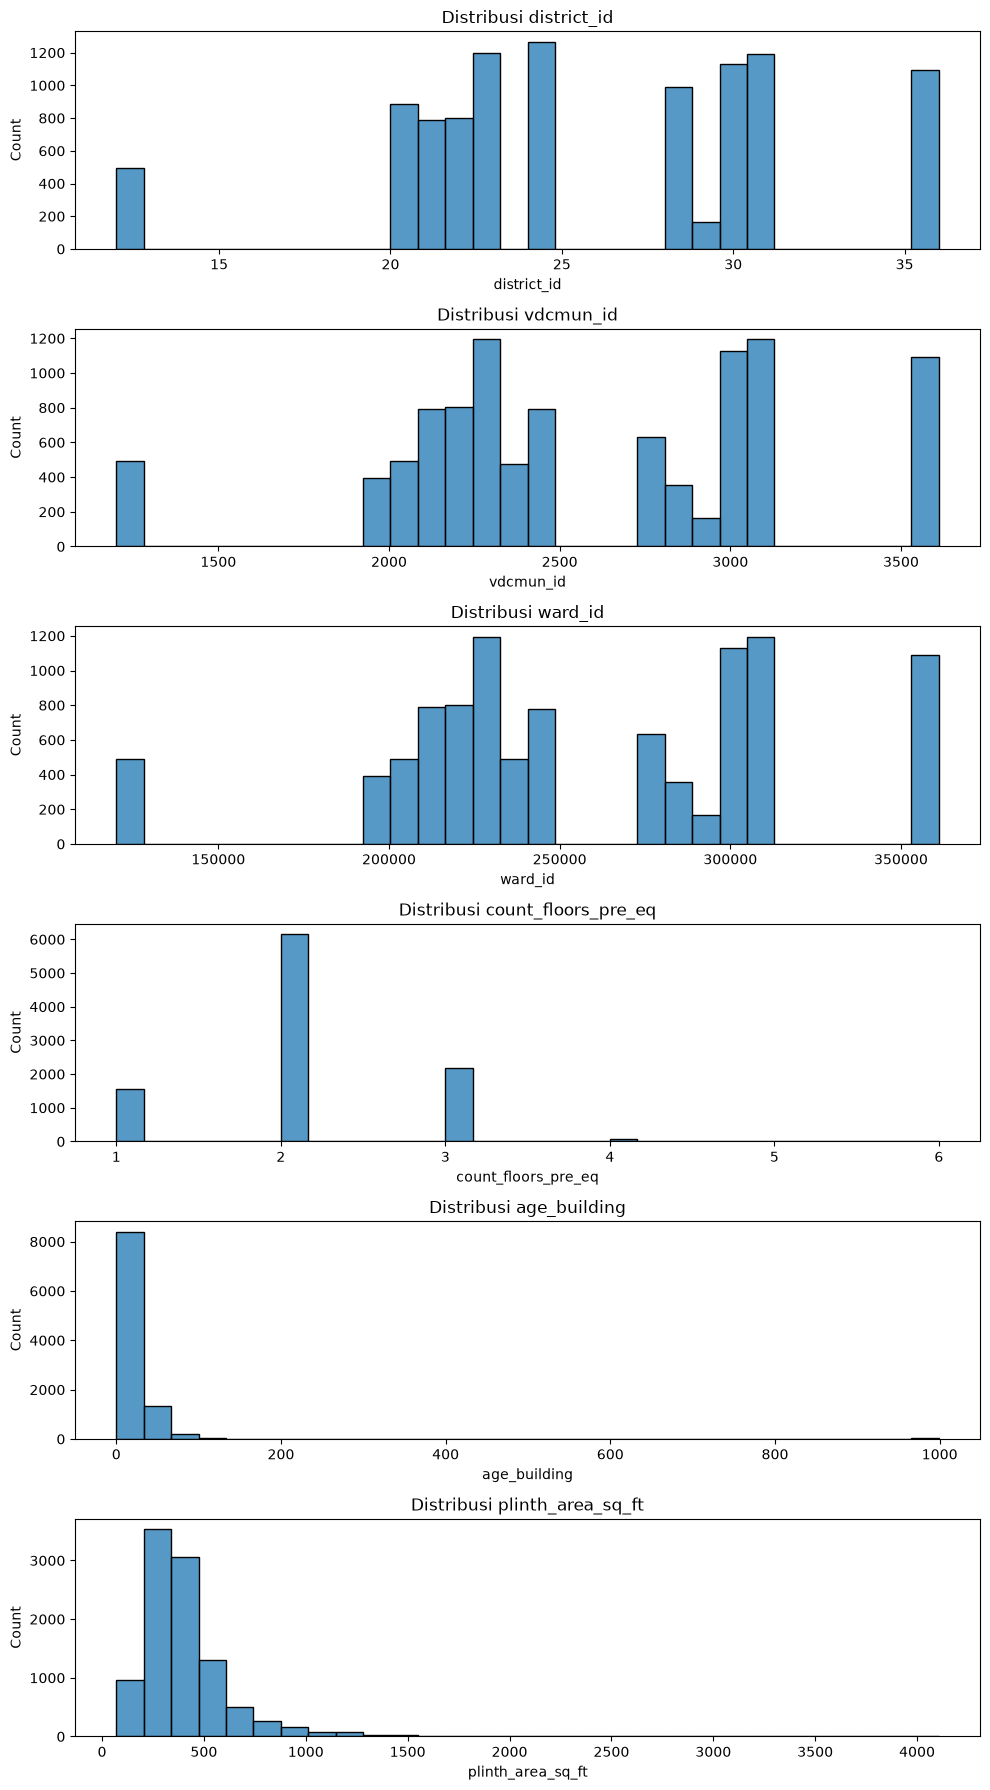

In [15]:
eda_sample = df.sample(
    n=min(10000, len(df)),
    random_state=42
)

numeric_plot = numerical_features[:6]

if numeric_plot:
    fig, axes = plt.subplots(
        len(numeric_plot),
        1,
        figsize=(10, 3 * len(numeric_plot))
    )

    axes = np.atleast_1d(axes)

    for ax, col in zip(axes, numeric_plot):
        sns.histplot(
            data=eda_sample,
            x=col,
            bins=30,
            kde=False,
            ax=ax
        )

        ax.set_title(f"Distribusi {col}")

    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada fitur numerik untuk divisualisasikan.")

##### **Statistika Deskriptif Fitur Kategorikal**

In [16]:
for col in categorical_features[:10]:
    print(f"\nDistribusi {col}:")
    display(
        df[col]
        .value_counts(dropna=False)
        .head(10)
        .to_frame("Jumlah")
    )


Distribusi land_surface_condition:


,Jumlah
land_surface_condition,
Flat,442089
Moderate slope,73944
Steep slope,17432



Distribusi foundation_type:


,Jumlah
foundation_type,
Mud mortar-Stone/Brick,440105
Bamboo/Timber,40167
Cement-Stone/Brick,27562
RC,22445
Other,3186



Distribusi roof_type:


...

,Jumlah
position,
Not attached,423151
Attached-1 side,90493
Attached-2 side,18943
Attached-3 side,878



Distribusi plan_configuration:


,Jumlah
plan_configuration,
Rectangular,511999
Square,12229
L-shape,7009
T-shape,668
Multi-projected,636
Others,387
U-shape,313
E-shape,99
Building with Central Courtyard,64



Distribusi superstructure:


,Jumlah
superstructure,
has_superstructure_mud_mortar_stone,415327
has_superstructure_cement_mortar_brick,33289
has_superstructure_timber,25407
has_superstructure_adobe_mud,22574
has_superstructure_rc_non_engineered,9051
has_superstructure_stone_flag,6994
has_superstructure_mud_mortar_brick,6746
has_superstructure_rc_engineered,5475
has_superstructure_cement_mortar_stone,4946


##### **Visualisasi Fitur Kategorikal**

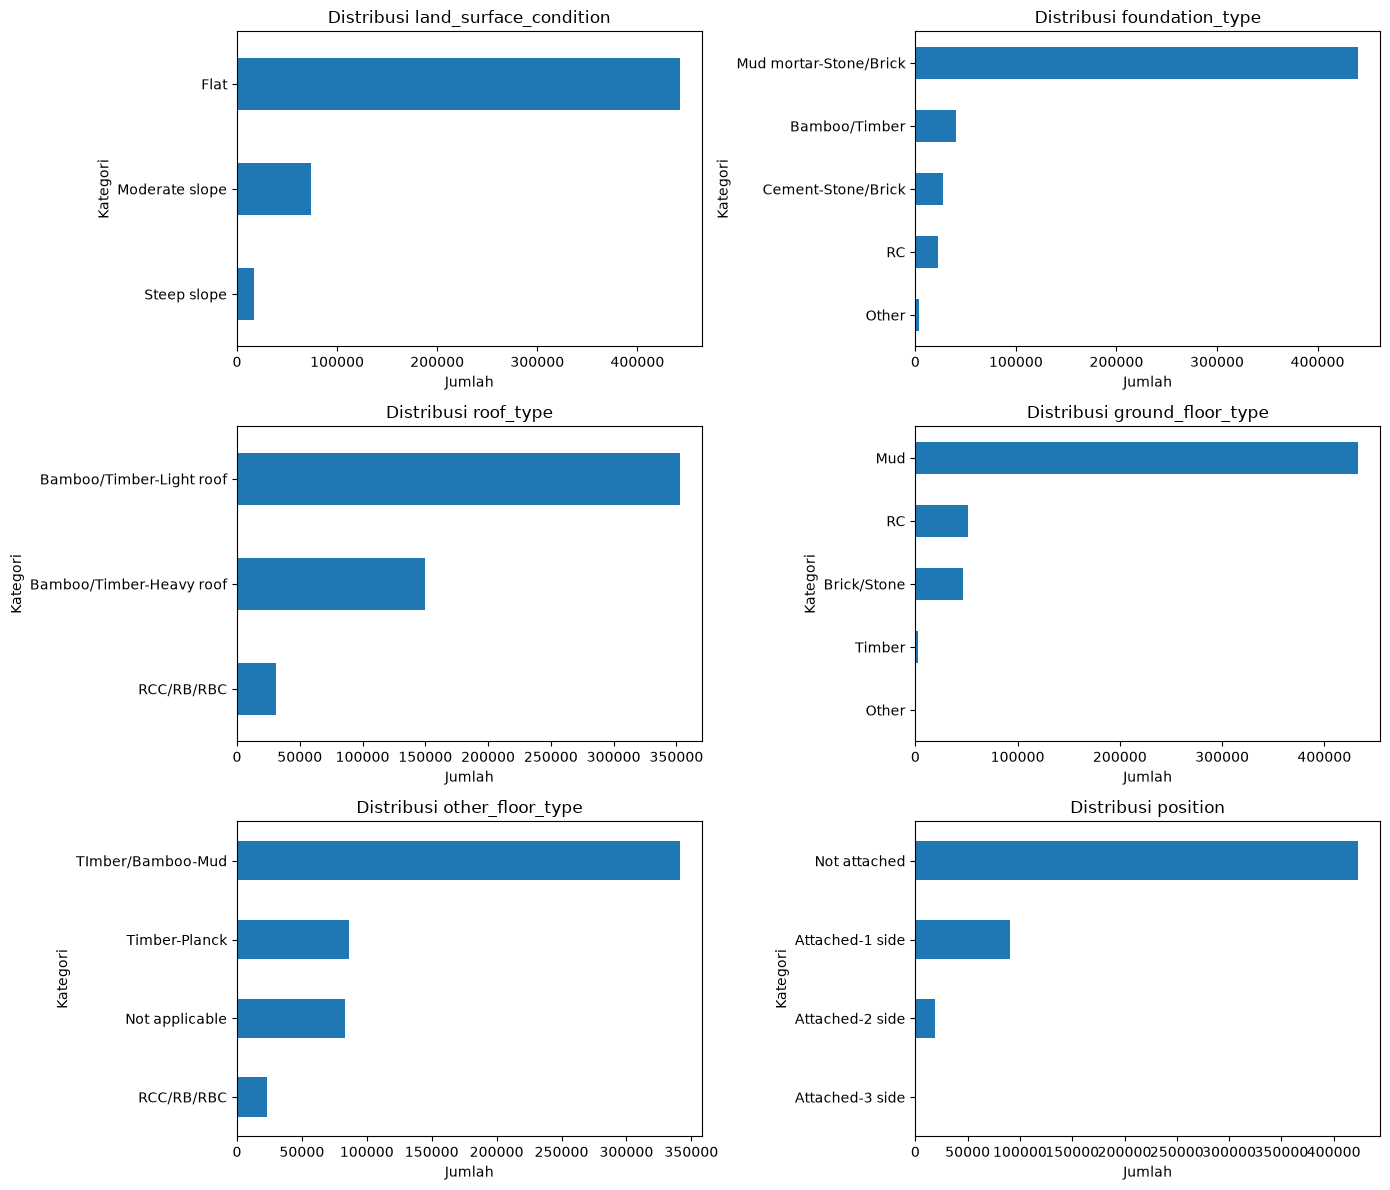

In [17]:
categorical_plot = categorical_features[:6]

if categorical_plot:
    n_cols = 2
    n_rows = int(np.ceil(len(categorical_plot) / n_cols))

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(14, 4 * n_rows)
    )

    axes = np.atleast_1d(axes).flatten()

    for ax, col in zip(axes, categorical_plot):
        counts = (
            df[col]
            .value_counts(dropna=False)
            .head(10)
            .sort_values()
        )

        counts.plot(
            kind="barh",
            ax=ax
        )

        ax.set_title(f"Distribusi {col}")
        ax.set_xlabel("Jumlah")
        ax.set_ylabel("Kategori")

    for ax in axes[len(categorical_plot):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada fitur kategorikal untuk divisualisasikan.")